# 13 · Training log, with reorders and arrivals

> **Engine-line study.** Notebooks 09–14 belong to the earlier latent-replenishment study on the full engine (`src/jepa/`, ADRs 0024–0032). Its published result, in `docs/jepa-replenishment.md` and `docs/paper/`, is that the latent planner did not beat a tuned order-up-to rule. The follow-up is the perfect-supplier line (notebook 15, ADR 0033).

Loads the published transition log at `runs/jepa-replenishment/log/transitions.parquet` into one pandas frame. One row is one product on one day. Ticks run from 1 through 364: the collector simulates 365 days and drops the last day, because that day has no next state. Day 365's on-hand and pipeline are `next_on_hand` and `next_in_transit` on tick 364.

`split` is the published fit's holdout. `_holdout_episodes` with seed 0 holds out one fifth of the episodes, and a whole episode stays on one side. The fit also stores those ids as `val_episodes` in `runs/jepa-replenishment/checkpoints/planner.json`, which notebook 14 reads. This notebook recomputes the split from the log, so it needs only the parquet.

Three episode totals are attached to every row:

- `n_reorders` — how many days the shop placed an order. A day counts once, however many products were on it. An order of 200 units in May and 500 units in October is 2.
- `reorder_qty` — units requested on those days. The same two orders are 700.
- `n_arrived_reorders` — product-days on which a positive quantity leaves the in-transit pipeline. The quantity is `sum(in_transit) + filled_qty - sum(next_in_transit)`. Age 0 of the profile is empty at the decision, and this tick's fill is what enters the pipeline.

A single request can arrive on more than one later day, because the three suppliers for a product have different lead times. An order placed in the last few days can still be on the way at the end of the episode.


In [7]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch

while not (Path.cwd() / "pyproject.toml").exists():
    os.chdir("..")

from src.jepa.dynamics import _holdout_episodes

LOG_PATH = Path("runs/jepa-replenishment/log/transitions.parquet")
if not LOG_PATH.is_file():
    raise FileNotFoundError(
        f"{LOG_PATH} is missing. The published collect command is in the root README."
    )


def _list_totals(table, name):
    """Sum each fixed-width list cell. The log's profiles do not vary in length."""
    lists = table.column(name).combine_chunks()
    offsets = np.asarray(lists.offsets.to_numpy(zero_copy_only=False))
    widths = np.diff(offsets)
    if len(widths) == 0 or not np.all(widths == widths[0]):
        raise ValueError(f"{name} lists are not a fixed width")
    values = np.asarray(lists.values.to_numpy(zero_copy_only=False))
    return values.reshape(len(lists), int(widths[0])).sum(axis=1)


table = pq.read_table(LOG_PATH)
arrived_qty = (
    _list_totals(table, "in_transit")
    + table.column("filled_qty").to_numpy()
    - _list_totals(table, "next_in_transit")
)
if np.any(arrived_qty < 0):
    raise ValueError("pipeline identity went negative; arrival count would be wrong")

seeds = table.column("episode_seed").to_numpy()
ticks = table.column("tick").to_numpy()
requested = table.column("requested_qty").to_numpy()
by_day = pd.DataFrame(
    {"episode_seed": seeds, "tick": ticks, "requested_qty": requested}
)
by_day["ordered"] = by_day["requested_qty"] > 0
by_day = by_day.groupby(["episode_seed", "tick"], sort=False).agg(
    requested_qty=("requested_qty", "sum"),
    ordered=("ordered", "any"),
)
reorders = by_day.groupby("episode_seed", sort=False).agg(
    n_reorders=("ordered", "sum"),
    reorder_qty=("requested_qty", "sum"),
)
arrivals = (
    pd.DataFrame({"episode_seed": seeds, "arrived": arrived_qty > 0})
    .groupby("episode_seed", sort=False)
    .sum(numeric_only=True)
    .rename(columns={"arrived": "n_arrived_reorders"})
)
counts = reorders.join(arrivals)

train_ids, val_ids = _holdout_episodes(
    pd.unique(seeds),
    torch.Generator().manual_seed(0),
)
split_of = {int(seed): "validation" for seed in val_ids}
split_of.update({int(seed): "train" for seed in train_ids})

frame = table.to_pandas()
del table
frame["arrived_qty"] = arrived_qty
frame["n_reorders"] = frame["episode_seed"].map(counts["n_reorders"]).astype(int)
frame["reorder_qty"] = frame["episode_seed"].map(counts["reorder_qty"]).astype(int)
frame["n_arrived_reorders"] = (
    frame["episode_seed"].map(counts["n_arrived_reorders"]).astype(int)
)
frame["split"] = frame["episode_seed"].map(split_of)

print(f"{len(frame):,} rows, {frame['episode_seed'].nunique()} episodes")
print(frame.groupby("split")["episode_seed"].nunique().to_string())
print("ticks", int(frame["tick"].min()), "through", int(frame["tick"].max()))


5,207,748 rows, 896 episodes
split
train         717
validation    179
ticks 1 through 364


In [8]:
frame

,episode_seed,behavior,tick,product_id,on_hand,in_transit,sales_window,cash,capacity,requested_qty,filled_qty,delivery_lag,next_on_hand,next_in_transit,next_sales,arrived_qty,n_reorders,reorder_qty,n_arrived_reorders,split
0,14000000,order_up_to,1,P0001,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",229936.948208,2133,0,0,2,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,350,23906,1255,train
1,14000000,order_up_to,1,P0034,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",229936.948208,2133,0,0,2,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,350,23906,1255,train
2,14000000,order_up_to,1,P0039,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",229936.948208,2133,0,0,2,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,350,23906,1255,train
3,14000000,order_up_to,1,P0079,91,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",229936.948208,2133,0,0,2,91,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,350,23906,1255,train
4,14000000,order_up_to,1,P0245,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",229936.948208,2133,0,0,2,92,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,350,23906,1255,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5207743,14000895,over_order,364,P0632,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-160269.569362,3392,1,0,2,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,364,1867152,1725,train
5207744,14000895,over_order,364,P0637,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-160269.569362,3392,1,0,2,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,364,1867152,1725,train
5207745,14000895,over_order,364,P0684,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-160269.569362,3392,1,0,2,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,364,1867152,1725,train
5207746,14000895,over_order,364,P0689,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-160269.569362,3392,1,0,2,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,364,1867152,1725,train


## One row per episode

`episodes` repeats nothing. `n_reorders`, `reorder_qty`, and `n_arrived_reorders` are the same numbers carried on every day of that episode in `frame`.


In [9]:
episodes = (
    frame.groupby(["episode_seed", "behavior", "split"], sort=False)
    .agg(
        n_days=("tick", "nunique"),
        n_skus=("product_id", "nunique"),
        n_reorders=("n_reorders", "first"),
        reorder_qty=("reorder_qty", "first"),
        n_arrived_reorders=("n_arrived_reorders", "first"),
    )
    .reset_index()
)
episodes


,episode_seed,behavior,split,n_days,n_skus,n_reorders,reorder_qty,n_arrived_reorders
0,14000000,order_up_to,train,364,16,350,23906,1255
1,14000001,order_up_to,train,364,2,10,1390,15
2,14000002,order_up_to,validation,364,28,295,12438,744
3,14000003,order_up_to,train,364,24,336,35031,1351
4,14000004,order_up_to,train,364,19,127,3369,304
...,...,...,...,...,...,...,...,...
891,14000891,over_order,train,364,17,364,651355,470
892,14000892,over_order,train,364,3,364,21960,35
893,14000893,over_order,validation,364,7,364,1692103,1247
894,14000894,over_order,train,364,2,364,45488,183


In [16]:
episodes_per_sku = (
    frame.groupby(["episode_seed", "behavior", "split", "product_id"], sort=False)
    .agg(
        n_days=("tick", "nunique"),
        n_reorders=("n_reorders", "first"),
        reorder_qty=("reorder_qty", "first"),
        n_arrived_reorders=("n_arrived_reorders", "first"),
    )
    .reset_index()
    .sort_values("n_reorders")
)
episodes_per_sku

,episode_seed,behavior,split,product_id,n_days,n_reorders,reorder_qty,n_arrived_reorders
5056,14000321,never_order,train,P0199,364,0,0,0
5686,14000360,never_order,train,P0211,364,0,0,0
5687,14000360,never_order,train,P0237,364,0,0,0
5688,14000360,never_order,train,P0274,364,0,0,0
5689,14000360,never_order,train,P0285,364,0,0,0
...,...,...,...,...,...,...,...,...
8710,14000546,over_order,train,P0285,364,364,24146504,2702
8709,14000546,over_order,train,P0264,364,364,24146504,2702
8708,14000546,over_order,train,P0249,364,364,24146504,2702
8706,14000546,over_order,train,P0171,364,364,24146504,2702


In [10]:
episodes.groupby(["split", "behavior"])[
    ["n_reorders", "reorder_qty", "n_arrived_reorders"]
].agg(["mean", "min", "max"])


n_reorders             reorder_qty        \
                                       mean  min  max          mean   min   
split      behavior                                                         
train      exploratory           244.377778    8  364  1.162632e+05    43   
           never_order             0.000000    0    0  0.000000e+00     0   
           order_up_to           168.959184    1  363  1.068876e+04     3   
           over_order            364.000000  364  364  5.349166e+06   364   
           periodic_order_up_to   74.185185    0  364  7.677000e+03     0   
           periodic_reorder       30.824561    0  259  3.557649e+03     0   
           reorder_point         210.775510   21  363  5.327449e+03   289   
validation exploratory           256.210526    0  363  9.933742e+04     0   
           never_order             0.000000    0    0  0.000000e+00     0   
           order_up_to           215.600000   19  336  1.180547e+04  1965   
           over_order            364.000000  364  364  5.315858e+06   488   
           periodic_order_up_to   74.500000    3  364  9.503700e+03     7   
           periodic_reorder       26.571429    0   88  4.050286e+03     0   
           reorder_point         190.266667   14  363  6.906333e+03   176   

                                          n_arrived_reorders            
                                      max               mean min   max  
split      behavior                                                     
train      exploratory             570032         713.866667   1  2301  
           never_order                  0           0.000000   0     0  
           order_up_to              35031         487.306122   3  1532  
           over_order            75652155        1262.653563   0  7847  
           periodic_order_up_to     49981         423.518519   0  3150  
           periodic_reorder         21308         124.070175   0  1428  
           reorder_point            18992         649.204082  50  2815  
validation exploratory             493325         696.210526   0  2220  
           never_order                  0           0.000000   0     0  
           order_up_to              25110         535.266667  35  1040  
           over_order            89405318        1122.523810   3  6986  
           periodic_order_up_to     29191         437.900000   6  1411  
           periodic_reorder         15875         121.857143   0   450  
           reorder_point            24594         558.400000  13  1559

## One product in one episode

Each episode is one shop. `plot_product` draws that shop's series for a single product. The three unit panels share one vertical scale, so stock, sales, and order size can be compared. Shop capacity is the whole shelf, not this product, so it is named in the inventory title instead of drawn as a line. Cash stays on its own scale. On-hand, in-transit, and cash are the values at the decision. Sales are the units the shop sold on that tick, the last entry of `sales_window`. Requested and filled are that tick's order. `arrived_qty` is the units that leave the pipeline before the next decision.


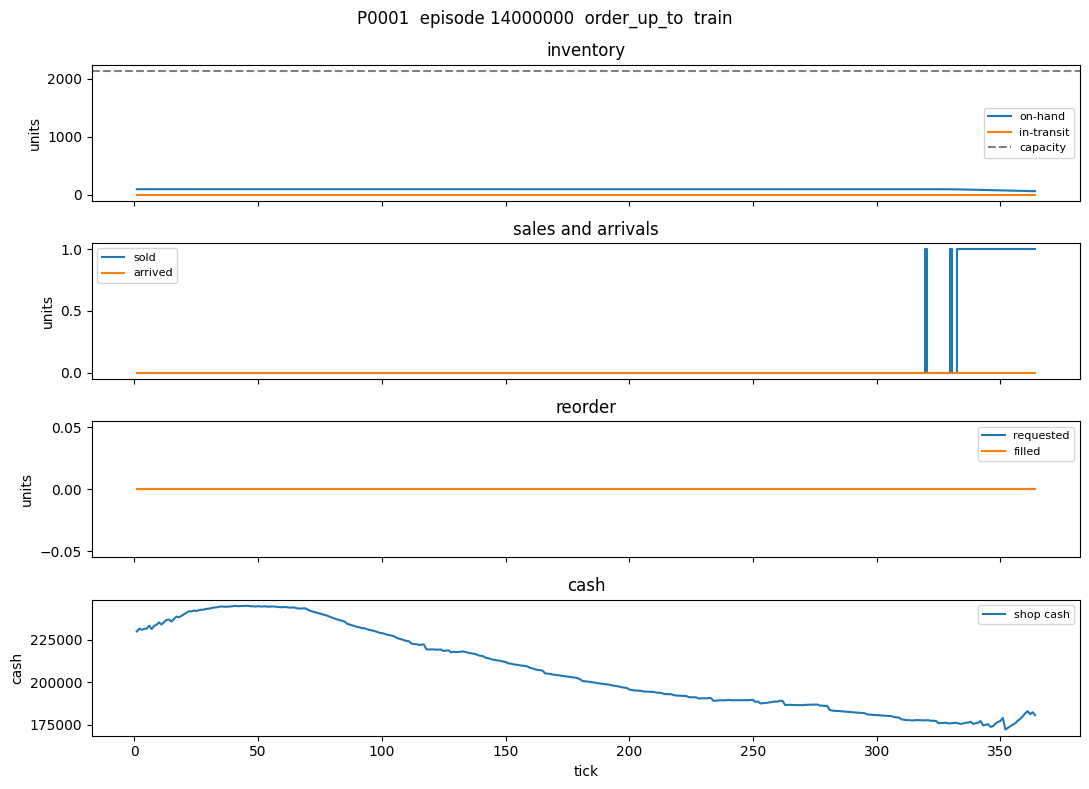

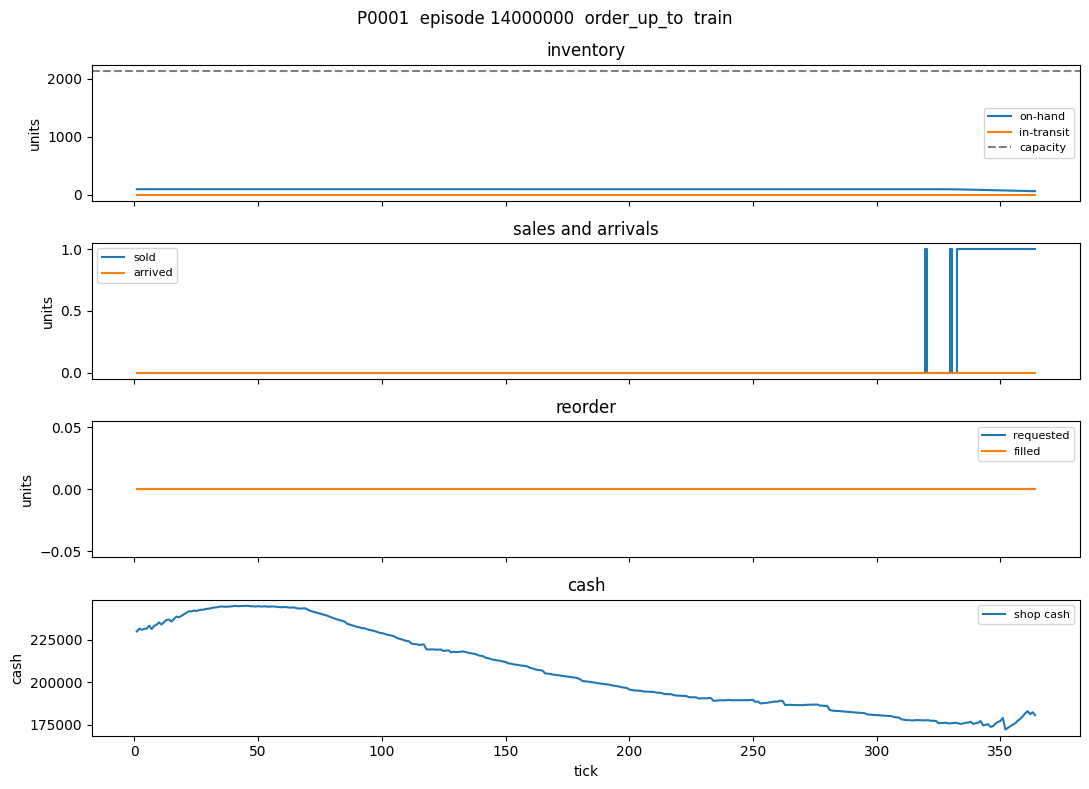

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt


def plot_product(frame, episode_seed, product_id):
    """Cash, stock, orders, sales, and arrivals for one product in one episode."""
    sku = frame.loc[
        (frame["episode_seed"] == int(episode_seed))
        & (frame["product_id"] == product_id)
    ].sort_values("tick")
    if sku.empty:
        raise KeyError(f"no rows for episode {episode_seed} product {product_id}")

    tick = sku["tick"].to_numpy()
    sales = sku["sales_window"].map(lambda window: int(window[-1])).to_numpy()
    on_the_way = sku["in_transit"].map(lambda profile: int(np.sum(profile))).to_numpy()
    behavior = sku["behavior"].iloc[0]
    split = sku["split"].iloc[0]

    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    fig.suptitle(
        f"{product_id}  episode {int(episode_seed)}  {behavior}  {split}"
    )

    axes[0].plot(tick, sku["on_hand"], label="on-hand")
    axes[0].plot(tick, on_the_way, label="in-transit")
    axes[0].set_ylabel("units")
    axes[0].set_title(f"inventory  ·  shop capacity {int(sku['capacity'].iloc[0])}")
    axes[0].legend(fontsize=8)

    axes[1].step(tick, sales, where="mid", label="sold")
    axes[1].step(tick, sku["arrived_qty"], where="mid", label="arrived")
    axes[1].set_ylabel("units")
    axes[1].set_title("sales and arrivals")
    axes[1].legend(fontsize=8)

    axes[2].step(tick, sku["requested_qty"], where="mid", label="requested")
    axes[2].step(tick, sku["filled_qty"], where="mid", label="filled")
    axes[2].set_ylabel("units")
    axes[2].set_title("reorder")
    axes[2].legend(fontsize=8)

    # One scale for every series counted in units. Shop capacity is the
    # whole shelf, so it is not included; it would flatten this product.
    unit_max = max(
        float(sku["on_hand"].max()),
        float(on_the_way.max()) if len(on_the_way) else 0.0,
        float(sales.max()) if len(sales) else 0.0,
        float(sku["arrived_qty"].max()),
        float(sku["requested_qty"].max()),
        float(sku["filled_qty"].max()),
    )
    for ax in axes[:3]:
        ax.set_ylim(0, max(unit_max * 1.05, 1))

    axes[3].plot(tick, sku["cash"], label="shop cash")
    axes[3].set_ylabel("cash")
    axes[3].set_xlabel("tick")
    axes[3].set_title("cash")
    axes[3].legend(fontsize=8)

    fig.tight_layout()
    # Returning the figure displays it. Closing it keeps the inline
    # backend from drawing that same figure a second time.
    plt.close(fig)
    return fig


In [12]:
frame[frame["episode_seed"] == 14000001]

,episode_seed,behavior,tick,product_id,on_hand,in_transit,sales_window,cash,capacity,requested_qty,filled_qty,delivery_lag,next_on_hand,next_in_transit,next_sales,arrived_qty,n_reorders,reorder_qty,n_arrived_reorders,split
5824,14000001,order_up_to,1,P0304,179,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",16177.330489,944,0,0,5,179,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,10,1390,15,train
5825,14000001,order_up_to,1,P0522,176,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",16177.330489,944,0,0,5,173,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",3,0,10,1390,15,train
5826,14000001,order_up_to,2,P0304,179,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",16172.212845,944,0,0,5,179,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,10,1390,15,train
5827,14000001,order_up_to,2,P0522,173,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",16172.212845,944,0,0,5,170,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",3,0,10,1390,15,train
5828,14000001,order_up_to,3,P0304,179,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",16167.365200,944,0,0,5,179,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,10,1390,15,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6547,14000001,order_up_to,362,P0522,22,"[0, 0, 224, 0, 0, 0, 0, 0, 0, 0]","[2, 6, 2, 5, 2, 2, 10, 4, 10, 11, 5, 8, 4, 7, ...",5958.908301,944,0,0,5,15,"[0, 0, 0, 224, 0, 0, 0, 0, 0, 0]",7,0,10,1390,15,train
6548,14000001,order_up_to,363,P0304,65,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, ...",6035.509288,944,0,0,5,65,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,0,10,1390,15,train
6549,14000001,order_up_to,363,P0522,15,"[0, 0, 0, 224, 0, 0, 0, 0, 0, 0]","[6, 2, 5, 2, 2, 10, 4, 10, 11, 5, 8, 4, 7, 9, ...",6035.509288,944,0,0,5,8,"[0, 0, 0, 0, 224, 0, 0, 0, 0, 0]",7,0,10,1390,15,train
6550,14000001,order_up_to,364,P0304,65,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, ...",6097.971451,944,0,0,5,64,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",1,0,10,1390,15,train


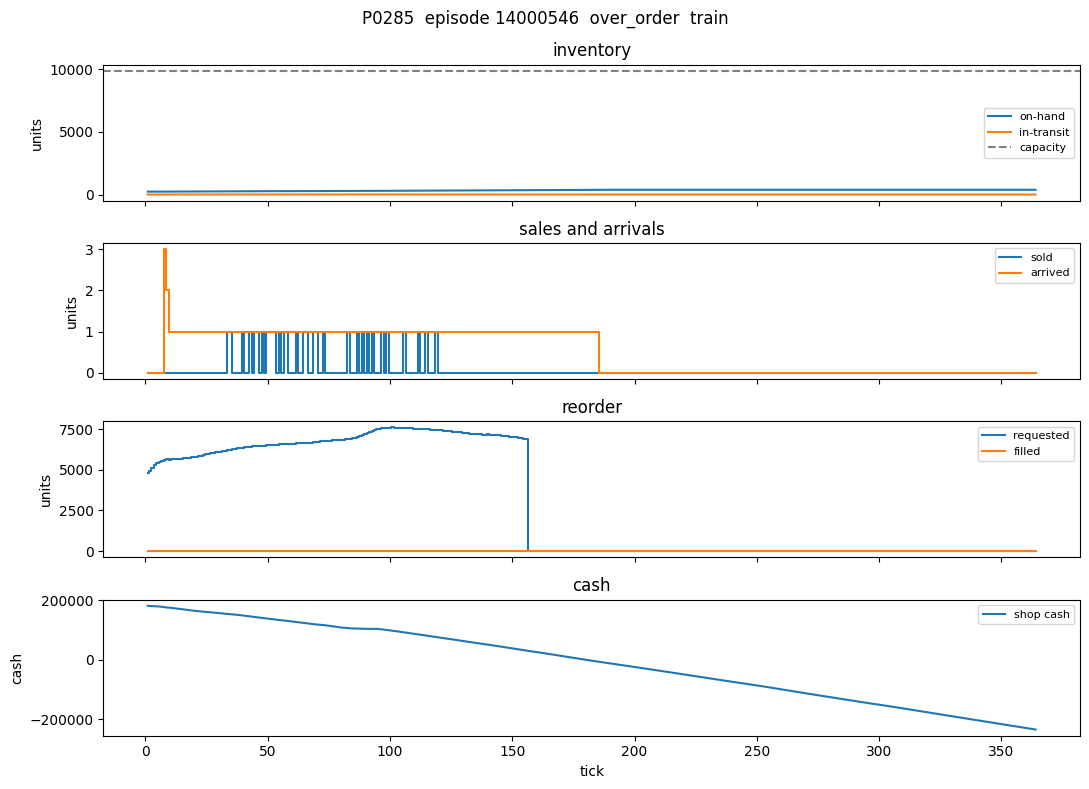

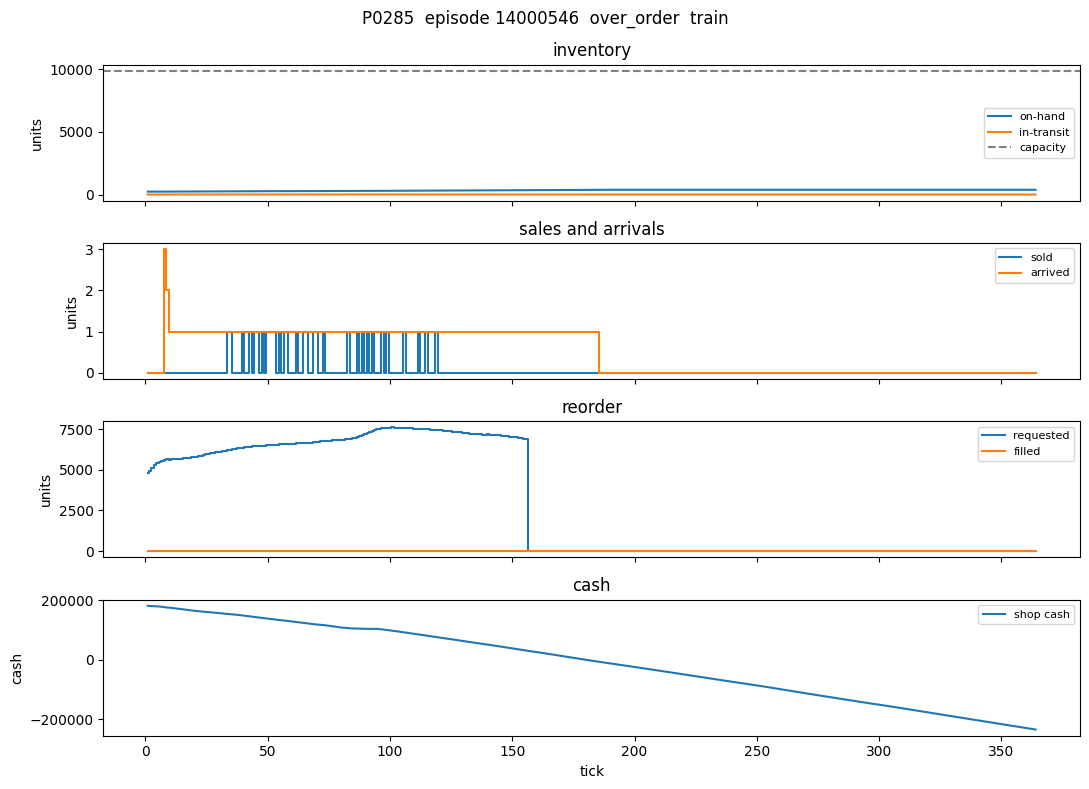

In [17]:
plot_product(frame, 14000546, "P0285")
